In [2]:
from pathlib import Path

# On remonte depuis le dossier du notebook jusqu'à trouver la racine du projet
ICI = Path.cwd()
RACINE = next(p for p in [ICI, *ICI.parents] if p.name == "nutri_private")

DOSSIER = RACINE / "data" / "images"

print("Dossier du notebook :", ICI)
print("Images cherchées dans :", DOSSIER)
print("Le dossier existe ?", DOSSIER.exists())

Dossier du notebook : c:\Users\Administrateur\Documents\nutri_private\src\images
Images cherchées dans : c:\Users\Administrateur\Documents\nutri_private\data\images
Le dossier existe ? True


In [3]:
from pathlib import Path
from collections import Counter

effectifs = Counter(p.parent.name for p in DOSSIER.glob("*/*.jpg"))
for rayon, n in sorted(effectifs.items()):
    print(f"{rayon:12s} {n}")

biscuits     500
charcuteries 500
chips        500
fromages     500
pates        500
sauces       500
sodas        500
yaourts      500


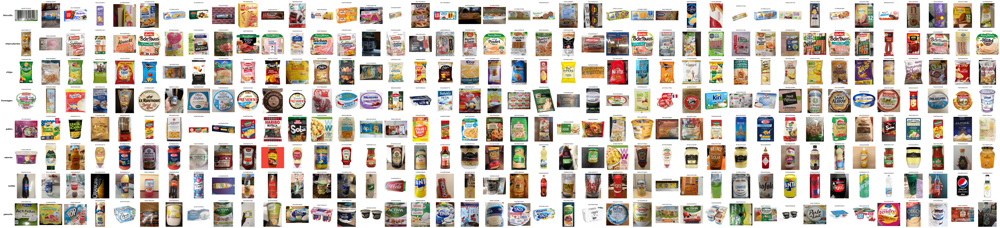

In [4]:
import random
import matplotlib.pyplot as plt
from PIL import Image

N_PAR_RAYON = 40
random.seed(42)  # même tirage à chaque exécution, pratique pour commenter les mêmes photos

rayons = sorted(d.name for d in DOSSIER.iterdir() if d.is_dir())

fig, axes = plt.subplots(len(rayons), N_PAR_RAYON,
                         figsize=(2 * N_PAR_RAYON, 2.3 * len(rayons)))

for i, rayon in enumerate(rayons):
    photos = sorted((DOSSIER / rayon).glob("*.jpg"))
    tirage = random.sample(photos, min(N_PAR_RAYON, len(photos)))

    for j in range(N_PAR_RAYON):
        ax = axes[i, j]
        ax.axis("off")
        if j < len(tirage):
            ax.imshow(Image.open(tirage[j]).convert("RGB"))
            ax.set_title(tirage[j].stem, fontsize=7)   # code-barres du produit
    axes[i, 0].text(-0.1, 0.5, rayon, transform=axes[i, 0].transAxes,
                    ha="right", va="center", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

visualisation de 40 produits par rayon : sodas yaourts biscuits fromages chips pates sauces charcuteries, on peut remarquer un seul code barre sur toute ces photos ( biscuit 482307761642 ), cas marginal on décide de ne pas enlever du set, on peux voir des photos de produit tenu dans la main, a des distances inégales sur rayon sodas et yaourt par exemple, le modèle devra donc pouvoir reconnaitre un produit indépendamment de sa taille dans l'image et des éléments parasites, main, fond

pistes d'augmentation : 

distance de prise de vue variable	zoom / recadrage aléatoire (RandomZoom, RandomResizedCrop)  
photos à la main légèrement de travers / petite rotation (quelques degrés, pas 90°)  
éclairage variable	variation de luminosité / contraste  
élements parasite : main et fond de la photo / pas de réelle solutions, recadra aléatoire aidera un peu mais c'est surtout le transfert depuis un réseau pré-entrainé qui aidera le plus

Les augmentations ne seront appliqués qu'au jeu d'entraînement après le découpage.

### CNN de ZERO, toutes les étapes :

In [5]:
from PIL import Image

illisibles = []
for p in DOSSIER.glob("*/*.jpg"):
    try:
        with Image.open(p) as img:
            img.verify()
    except Exception:
        illisibles.append(p)
print(f"{len(illisibles)} image(s) illisible(s)", illisibles[:10])

0 image(s) illisible(s) []


0 images illisibles on procède

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.DataFrame({"chemin": [p.relative_to(RACINE).as_posix() for p in DOSSIER.glob("*/*.jpg")]})
df["rayon"] = df["chemin"].map(lambda c: Path(c).parent.name)

train, temp = train_test_split(df, test_size=0.30, stratify=df["rayon"], random_state=42)
val, test = train_test_split(temp, test_size=0.50, stratify=temp["rayon"], random_state=42)

decoupage = pd.concat([train.assign(split="train"),
                       val.assign(split="val"),
                       test.assign(split="test")])
decoupage.to_csv(RACINE / "data" / "decoupage.csv", index=False)

# Vérification : chaque rayon doit avoir ~70/15/15 %
print(pd.crosstab(decoupage["rayon"], decoupage["split"], margins=True))

split         test  train  val   All
rayon                               
biscuits        75    350   75   500
charcuteries    75    350   75   500
chips           75    350   75   500
fromages        75    350   75   500
pates           75    350   75   500
sauces          75    350   75   500
sodas           75    350   75   500
yaourts         75    350   75   500
All            600   2800  600  4000


Découpage fait

chaque rayon est bien réparti à environ 70/15/15 %

In [7]:
import numpy as np
import pandas as pd
from PIL import Image

TAILLE = 96  # pixels, petite taille, suffisant pour un CNN de zéro et rapide sur CPU

decoupage = pd.read_csv(RACINE / "data" / "decoupage.csv")
classes = sorted(decoupage["rayon"].unique())
rayon_vers_indice = {r: i for i, r in enumerate(classes)}

def charger(split):
    partie = decoupage[decoupage["split"] == split]
    X = np.stack([
        np.asarray(Image.open(RACINE / c).convert("RGB").resize((TAILLE, TAILLE)))
        for c in partie["chemin"]
    ])                                   # uint8, forme (N, 96, 96, 3)
    y = partie["rayon"].map(rayon_vers_indice).to_numpy()
    return X, y

X_train, y_train = charger("train")
X_val, y_val = charger("val")
# le test reste fermé jusqu'à l'étape 4

print("Classes :", classes)
print("Train :", X_train.shape, "— Val :", X_val.shape)

Classes : ['biscuits', 'charcuteries', 'chips', 'fromages', 'pates', 'sauces', 'sodas', 'yaourts']
Train : (2800, 96, 96, 3) — Val : (600, 96, 96, 3)


chargement de train et val depuis le découpage.csv OK

In [14]:
from tensorflow.keras import layers, models, callbacks
import keras

keras.utils.set_random_seed(42)

modele = models.Sequential([
    layers.Input(shape=(TAILLE, TAILLE, 3)),
    layers.Rescaling(1 / 255),           # normalisation intégrée au modèle

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(classes), activation="softmax"),
])

modele.compile(optimizer="adam",
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
modele.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,280 (368.28 KB)

 Trainable params: 94,280 (368.28 KB)

 Non-trainable params: 0 (0.00 B)

Mise en place du CNN de zéro ok 

ordre de grandeur de 100 000 environ, ce qui est logique vu qu'on a réduit les pixels d'image pour acélérrer l'entrainement, pas de non trainable params vu qu'on utilise pas encore de modèle déja pré entrainé dans lequel on gelera des couches de neurones plus tard

### ENTRAINEMENT

In [15]:
arret = callbacks.EarlyStopping(monitor="val_accuracy", patience=5,
                                restore_best_weights=True)

entrainement = modele.fit(X_train, y_train,
                        validation_data=(X_val, y_val),
                        epochs=40, batch_size=32,
                        callbacks=[arret])

Epoch 1/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.1407 - loss: 2.0720 - val_accuracy: 0.1900 - val_loss: 2.0386
Epoch 2/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.1943 - loss: 2.0242 - val_accuracy: 0.2633 - val_loss: 1.9782
Epoch 3/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - accuracy: 0.2186 - loss: 1.9914 - val_accuracy: 0.2950 - val_loss: 1.9287
Epoch 4/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.2489 - loss: 1.9415 - val_accuracy: 0.3000 - val_loss: 1.8955
Epoch 5/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.2575 - loss: 1.9205 - val_accuracy: 0.3200 - val_loss: 1.8774
Epoch 6/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.2821 - loss: 1.8934 - val_accuracy: 0.3183 - val_loss: 1.8652
Epoch 7/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.2918 - loss: 1.8576 - val_accuracy: 0.3417 - val_loss: 1.8229
Epoch 8/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.3193 - loss: 1.8397 - val_accuracy: 0.3200 - v

arrêt a 28 époque, une précision de 0.46 ce qui équivaut ~ a une chance sur 2, pas terrible mais sur un cnn a zero c'est attendu

Graphiques:

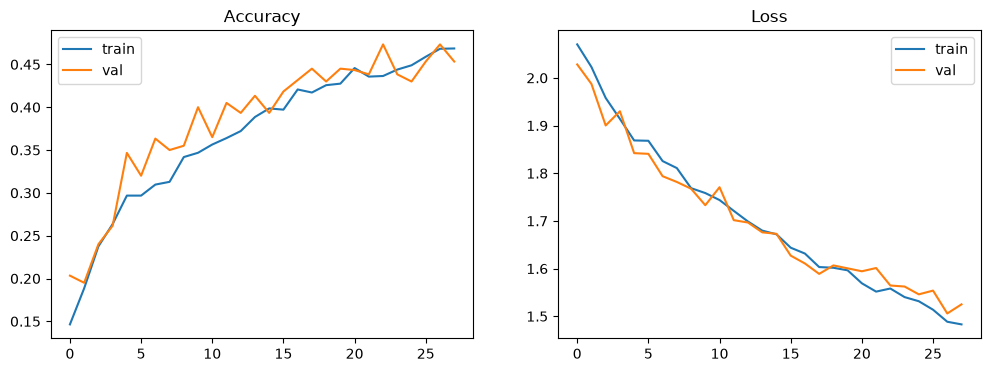

CNN de zéro (val)     : 47.3%
Hasard                : 12.5%
Classe majoritaire    : 12.5%
Plancher de l'énoncé  : [à compléter]


In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(entrainement.history["accuracy"], label="train")
ax1.plot(entrainement.history["val_accuracy"], label="val")
ax1.set_title("Accuracy"); ax1.legend()
ax2.plot(entrainement.history["loss"], label="train")
ax2.plot(entrainement.history["val_loss"], label="val")
ax2.set_title("Loss"); ax2.legend()
plt.show()

val_acc = max(entrainement.history["val_accuracy"])
hasard = 1 / len(classes)
majoritaire = np.bincount(y_val).max() / len(y_val)

print(f"CNN de zéro (val)     : {val_acc:.1%}")
print(f"Hasard                : {hasard:.1%}")
print(f"Classe majoritaire    : {majoritaire:.1%}")